# Black-box adversarial reliability and adversarial-cluster density

This experiment measures whether successful black-box adversarial examples concentrate in compact clusters. It uses the corrected version of Aidan's intended adversarial-cluster density calculation.

It is intentionally independent from the earlier white-box tree workflow:

- **Models:** decision tree, MLP, and RBF SVM.
- **Attacks:** HopSkipJump and Boundary Attack. Both see only a label-returning API; no gradients, parameters, tree structure, confidence scores, or training samples are passed to ART.
- **Density:** OPTICS clusters successful adversarial outputs. A cluster's score is its number of unique point pairs divided by their total pairwise separation plus one.
- **Reliability:** empirical robust accuracy at a fixed L2 budget, conservatively minimized across attacks. This is not a formal certificate.

The two-dimensional dataset is intentional: it lets us inspect attack paths and adversarial clusters. Cluster density is an attack-outcome diagnostic, not a pre-attack predictor or a formal robustness certificate.

In [2]:
from collections.abc import Callable
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from art.attacks.evasion import BoundaryAttack, HopSkipJump
from art.estimators.classification import BlackBoxClassifier
from sklearn.cluster import OPTICS
from sklearn.datasets import make_moons
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import accuracy_score
from sklearn.model_selection import StratifiedShuffleSplit, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore", category=ConvergenceWarning)

SEED = 19
QUICK_RUN = True
N_SAMPLES = 2_400
MOON_NOISE = 0.28
ATTACK_SAMPLE_SIZE = 80 if QUICK_RUN else 300
OPTICS_MIN_SAMPLES = 5
L2_BUDGET = 0.15
PROJECT_ROOT = next(
    directory
    for directory in (Path.cwd(), *Path.cwd().parents)
    if (directory / "pyproject.toml").is_file()
)
OUTPUT_DIR = PROJECT_ROOT / "data" / "black_box_density"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
for legacy_output in (
    "density_map.png",
    "density_risk_curves.png",
    "density_signal_summary.csv",
):
    (OUTPUT_DIR / legacy_output).unlink(missing_ok=True)

HSJ_PARAMETERS = {
    "max_iter": 8 if QUICK_RUN else 30,
    "max_eval": 250 if QUICK_RUN else 2_000,
    "init_eval": 25 if QUICK_RUN else 100,
    "init_size": 25 if QUICK_RUN else 100,
}
BOUNDARY_PARAMETERS = {
    "max_iter": 15 if QUICK_RUN else 250,
    "num_trial": 5 if QUICK_RUN else 15,
    "sample_size": 8 if QUICK_RUN else 20,
    "init_size": 25 if QUICK_RUN else 100,
}

print(
    f"quick_run={QUICK_RUN}; attack_samples={ATTACK_SAMPLE_SIZE}; "
    f"L2 budget={L2_BUDGET}; output={OUTPUT_DIR}"
)

quick_run=True; attack_samples=80; L2 budget=0.15; output=c:\Auditingv2\Auditing\data\black_box_density


## Data splits and models

The scaler is fitted only on the model-training split. `clip=True` defines a known `[0, 1]^2` valid-input box for the black-box attacks.

The attack inputs are a disjoint stratified subset of the evaluation split. Adversarial-cluster density is calculated only after each attack has returned successful adversarial outputs.

In [3]:
X_raw, y = make_moons(
    n_samples=N_SAMPLES,
    noise=MOON_NOISE,
    random_state=SEED,
)

X_model, X_evaluation, y_model, y_evaluation = train_test_split(
    X_raw,
    y,
    test_size=0.5,
    stratify=y,
    random_state=SEED,
)
scaler = MinMaxScaler(clip=True).fit(X_model)
X_model = scaler.transform(X_model).astype(np.float32)
X_evaluation = scaler.transform(X_evaluation).astype(np.float32)

attack_selector = StratifiedShuffleSplit(
    n_splits=1,
    train_size=ATTACK_SAMPLE_SIZE,
    random_state=SEED + 2,
)
attack_indices, _ = next(attack_selector.split(X_evaluation, y_evaluation))
X_attack = X_evaluation[attack_indices]
y_attack = y_evaluation[attack_indices]

models = {
    "decision_tree": DecisionTreeClassifier(
        max_depth=6,
        min_samples_leaf=8,
        random_state=SEED,
    ),
    "mlp": MLPClassifier(
        hidden_layer_sizes=(32, 32),
        alpha=1e-3,
        early_stopping=True,
        max_iter=1_000,
        random_state=SEED,
    ),
    "rbf_svm": SVC(
        C=2.0,
        kernel="rbf",
        probability=True,
        random_state=SEED,
    ),
}

for model in models.values():
    model.fit(X_model, y_model)

pd.DataFrame(
    {
        "split": ["model training", "evaluation", "attack"],
        "samples": [len(X_model), len(X_evaluation), len(X_attack)],
        "class_0": [(y_model == 0).sum(), (y_evaluation == 0).sum(), (y_attack == 0).sum()],
        "class_1": [(y_model == 1).sum(), (y_evaluation == 1).sum(), (y_attack == 1).sum()],
    }
)

c:\Users\johns\.conda\envs\environment\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,split,samples,class_0,class_1
0,model training,1200,600,600
1,evaluation,1200,600,600
2,attack,80,40,40


## Corrected adversarial-cluster density

For one model and one attack, retain only outputs `z_i` that changed the prediction of an initially correct input. OPTICS clusters these successful adversarial outputs; noise points are excluded.

For cluster `C_j` with `n_j` points, calculate:

`cluster_density(C_j) = choose(n_j, 2) / (1 + sum_{a < b} ||z_a - z_b||_2)`.

The reported adversarial-cluster density is the unweighted mean across non-noise clusters. In this two-dimensional experiment, `||z_a - z_b||_2` is also the Frobenius norm of the row-vector difference. Higher values mean points in a cluster are more tightly packed.

This preserves Aidan's intended `pair_count / (total_separation + 1)` formula, but fixes the original implementation: it sums distances **between** unique pairs rather than norms of coordinates from the origin, and it does not double-count or include self-pairs.

In [4]:
def adversarial_cluster_metrics(
    adversarial_points: np.ndarray,
    min_samples: int,
) -> tuple[dict[str, float | int], np.ndarray]:
    total_point_count = len(adversarial_points)
    if total_point_count < min_samples:
        return (
            {
                "adversarial_cluster_density": np.nan,
                "adversarial_cluster_count": 0,
                "clustered_adversarial_points": 0,
                "noise_adversarial_points": total_point_count,
            },
            np.full(total_point_count, -1, dtype=int),
        )

    cluster_labels = OPTICS(min_samples=min_samples).fit_predict(adversarial_points)
    labels = np.unique(cluster_labels[cluster_labels != -1])
    cluster_scores = []
    clustered_points = 0

    for label in labels:
        points = adversarial_points[cluster_labels == label]
        cluster_size = len(points)
        pair_count = cluster_size * (cluster_size - 1) // 2
        if pair_count == 0:
            continue
        pairwise_differences = points[:, np.newaxis, :] - points[np.newaxis, :, :]
        pairwise_distances = np.linalg.norm(pairwise_differences, axis=2)
        total_separation = pairwise_distances[np.triu_indices(cluster_size, k=1)].sum()
        cluster_scores.append(pair_count / (total_separation + 1.0))
        clustered_points += cluster_size

    return (
        {
            "adversarial_cluster_density": float(np.mean(cluster_scores))
            if cluster_scores
            else np.nan,
            "adversarial_cluster_count": len(cluster_scores),
            "clustered_adversarial_points": clustered_points,
            "noise_adversarial_points": total_point_count - clustered_points,
        },
        cluster_labels,
    )

## Label-only black-box attacks

`CountingLabelOracle` exposes only one-hot class labels. It has no `predict_proba`, gradient, model, or training-data attribute. ART sees that oracle through `BlackBoxClassifier`, so the two attack algorithms cannot inspect the scikit-learn estimators.

`attack_success_at_budget` is true only for initially correct inputs whose predicted label changes within `L2_BUDGET`. Query counts include all calls made through the attack oracle, including initial and final label checks. Each attack receives a deterministic initial point from the same attack batch whose label differs according to this oracle; this avoids ART's unseeded random initialization without exposing any model internals.

In [5]:
class CountingLabelOracle:
    def __init__(self, predict: Callable[[np.ndarray], np.ndarray], classes: np.ndarray):
        self._predict = predict
        self._classes = np.asarray(classes)
        self._class_to_index = {label: index for index, label in enumerate(self._classes)}
        self.queries = 0

    def __call__(self, inputs: np.ndarray) -> np.ndarray:
        inputs = np.asarray(inputs)
        self.queries += len(inputs)
        labels = self._predict(inputs)
        indices = np.fromiter(
            (self._class_to_index[label] for label in labels),
            dtype=int,
            count=len(labels),
        )
        return np.eye(len(self._classes), dtype=np.float32)[indices]


def deterministic_adversarial_initialization(
    inputs: np.ndarray,
    base_predictions: np.ndarray,
) -> np.ndarray:
    initial_indices = np.empty(len(inputs), dtype=int)
    for index, prediction in enumerate(base_predictions):
        alternatives = np.flatnonzero(base_predictions != prediction)
        if len(alternatives) == 0:
            raise ValueError(
                "The attack batch needs predictions from at least two classes "
                "to provide a deterministic adversarial initialization."
            )
        initial_indices[index] = alternatives[0]
    return inputs[initial_indices].copy()


def run_black_box_attack(
    model_name: str,
    model,
    attack_name: str,
    inputs: np.ndarray,
    labels: np.ndarray,
) -> pd.DataFrame:
    oracle = CountingLabelOracle(model.predict, model.classes_)
    black_box = BlackBoxClassifier(
        predict_fn=oracle,
        input_shape=(inputs.shape[1],),
        nb_classes=len(model.classes_),
        clip_values=(0.0, 1.0),
    )

    if attack_name == "hopskipjump":
        attack = HopSkipJump(
            classifier=black_box,
            targeted=False,
            norm=2,
            batch_size=32,
            verbose=False,
            **HSJ_PARAMETERS,
        )
    elif attack_name == "boundary":
        attack = BoundaryAttack(
            estimator=black_box,
            targeted=False,
            batch_size=32,
            verbose=False,
            **BOUNDARY_PARAMETERS,
        )
    else:
        raise ValueError(f"Unsupported attack: {attack_name}")

    base_predictions = oracle(inputs).argmax(axis=1)
    x_adv_init = deterministic_adversarial_initialization(inputs, base_predictions)
    adversarial = attack.generate(inputs.astype(np.float32), x_adv_init=x_adv_init)
    adversarial_predictions = oracle(adversarial).argmax(axis=1)
    perturbations = adversarial - inputs
    l2_distance = np.linalg.norm(perturbations, axis=1)
    linf_distance = np.max(np.abs(perturbations), axis=1)
    clean_correct = base_predictions == labels
    changed_label = adversarial_predictions != base_predictions
    attack_success = clean_correct & changed_label
    attack_success_at_budget = attack_success & (l2_distance <= L2_BUDGET)

    return pd.DataFrame(
        {
            "model": model_name,
            "attack": attack_name,
            "sample_index": np.arange(len(inputs)),
            "true_label": labels,
            "base_prediction": base_predictions,
            "adversarial_prediction": adversarial_predictions,
            "clean_correct": clean_correct,
            "changed_label": changed_label,
            "attack_success": attack_success,
            "attack_success_at_budget": attack_success_at_budget,
            "l2_distance": l2_distance,
            "linf_distance": linf_distance,
            "x0": inputs[:, 0],
            "x1": inputs[:, 1],
            "adv_x0": adversarial[:, 0],
            "adv_x1": adversarial[:, 1],
            "black_box_queries": oracle.queries,
        }
    )


clean_accuracy = {
    model_name: accuracy_score(y_evaluation, model.predict(X_evaluation))
    for model_name, model in models.items()
}
np.random.seed(SEED)
attack_results = pd.concat(
    [
        run_black_box_attack(model_name, model, attack_name, X_attack, y_attack)
        for model_name, model in models.items()
        for attack_name in ("hopskipjump", "boundary")
    ],
    ignore_index=True,
)

attack_results.head()

,model,attack,sample_index,true_label,base_prediction,adversarial_prediction,clean_correct,changed_label,attack_success,attack_success_at_budget,l2_distance,linf_distance,x0,x1,adv_x0,adv_x1,black_box_queries
0,decision_tree,hopskipjump,0,0,0,1,True,True,True,True,0.073842,0.073820,0.622258,0.508271,0.696078,0.506443,38772
1,decision_tree,hopskipjump,1,0,0,1,True,True,True,True,0.089341,0.071631,0.639995,0.591458,0.693388,0.519827,38772
2,decision_tree,hopskipjump,2,1,1,0,True,True,True,False,0.177432,0.149206,0.724262,0.273708,0.628243,0.422914,38772
3,decision_tree,hopskipjump,3,1,1,0,True,True,True,False,0.342554,0.292852,0.877696,0.293681,0.584844,0.471390,38772
4,decision_tree,hopskipjump,4,1,1,0,True,True,True,False,0.164075,0.163865,0.618727,0.268541,0.627015,0.432406,38772


## Reliability and adversarial-cluster metrics

For each attack, empirical robust accuracy is `1 - mean(attack_success_at_budget)` over all attack inputs. This convention counts already-misclassified inputs as non-robust. The conservative model score is the minimum empirical robust accuracy across attacks.

For each model/attack pair, the notebook reports the number of successful adversarial outputs, the number assigned to an OPTICS cluster, the number marked noise, the cluster count, and the mean corrected adversarial-cluster density. This density is calculated **after** attack success, so it describes the concentration of found failure modes; it must not be treated as a predictor of attack success or as a reliability score by itself.

In [6]:
def summarise_attack(group: pd.DataFrame) -> pd.Series:
    eligible = group["clean_correct"]
    successful = group.loc[eligible & group["attack_success"], "l2_distance"]
    return pd.Series(
        {
            "clean_accuracy": clean_accuracy[group.name[0]],
            "attack_inputs": len(group),
            "initially_correct": int(eligible.sum()),
            "conditional_attack_success_rate": group.loc[
                eligible, "attack_success"
            ].mean(),
            "empirical_robust_accuracy_at_l2_budget": 1.0
            - group["attack_success_at_budget"].mean(),
            "median_successful_boundary_l2": successful.median(),
            "queries_per_attack_input": group["black_box_queries"].iloc[0]
            / len(group),
        }
    )


attack_summary = (
    attack_results.groupby(["model", "attack"], sort=False)
    .apply(summarise_attack, include_groups=False)
    .reset_index()
)
cluster_rows = []
cluster_assignments = []
for (model_name, attack_name), group in attack_results.groupby(
    ["model", "attack"],
    sort=False,
):
    successful = group.loc[
        group["clean_correct"] & group["attack_success"]
    ].copy()
    metrics, labels = adversarial_cluster_metrics(
        successful[["adv_x0", "adv_x1"]].to_numpy(),
        OPTICS_MIN_SAMPLES,
    )
    metrics.update(
        {
            "model": model_name,
            "attack": attack_name,
            "successful_adversarial_points": len(successful),
        }
    )
    cluster_rows.append(metrics)
    successful["adversarial_cluster_label"] = labels
    cluster_assignments.append(
        successful[["model", "attack", "sample_index", "adversarial_cluster_label"]]
    )

cluster_summary = pd.DataFrame(cluster_rows)
cluster_assignments = pd.concat(cluster_assignments, ignore_index=True)
attack_results = attack_results.merge(
    cluster_assignments,
    how="left",
    on=["model", "attack", "sample_index"],
)
reliability_summary = (
    attack_summary.groupby("model", as_index=False)
    .agg(
        clean_accuracy=("clean_accuracy", "first"),
        empirical_reliability_at_l2_budget=(
            "empirical_robust_accuracy_at_l2_budget",
            "min",
        ),
        worst_conditional_attack_success_rate=(
            "conditional_attack_success_rate",
            "max",
        ),
    )
    .sort_values("empirical_reliability_at_l2_budget")
)

attack_results.to_csv(OUTPUT_DIR / "per_sample_outcomes.csv", index=False)
attack_summary.to_csv(OUTPUT_DIR / "attack_summary.csv", index=False)
cluster_summary.to_csv(OUTPUT_DIR / "adversarial_cluster_summary.csv", index=False)
reliability_summary.to_csv(OUTPUT_DIR / "reliability_summary.csv", index=False)

display(reliability_summary.round(3))
display(attack_summary.merge(cluster_summary, on=["model", "attack"]).round(3))

,model,clean_accuracy,empirical_reliability_at_l2_budget,worst_conditional_attack_success_rate
0,decision_tree,0.914,0.412,1.0
2,rbf_svm,0.925,0.462,1.0
1,mlp,0.871,0.825,1.0


,model,attack,clean_accuracy,attack_inputs,initially_correct,conditional_attack_success_rate,empirical_robust_accuracy_at_l2_budget,median_successful_boundary_l2,queries_per_attack_input,adversarial_cluster_density,adversarial_cluster_count,clustered_adversarial_points,noise_adversarial_points,successful_adversarial_points
0,decision_tree,hopskipjump,0.914,80.0,76.0,1.0,0.612,0.169,484.650,13.059,5,34,42,76
1,decision_tree,boundary,0.914,80.0,76.0,1.0,0.412,0.121,211.612,22.753,5,59,17,76
2,mlp,hopskipjump,0.871,80.0,67.0,1.0,0.875,0.305,484.000,11.333,5,50,17,67
3,mlp,boundary,0.871,80.0,67.0,1.0,0.825,0.225,205.925,17.094,6,42,25,67
4,rbf_svm,hopskipjump,0.925,80.0,75.0,1.0,0.700,0.188,484.012,17.776,3,55,20,75
5,rbf_svm,boundary,0.925,80.0,75.0,1.0,0.462,0.141,207.062,20.441,6,48,27,75


## Visual diagnostics

The arrows below are successful examples found by each black-box attack. The second chart shows the successful adversarial outputs: colours identify OPTICS clusters and grey marks noise. It visualizes the same points used in the corrected cluster-density formula.

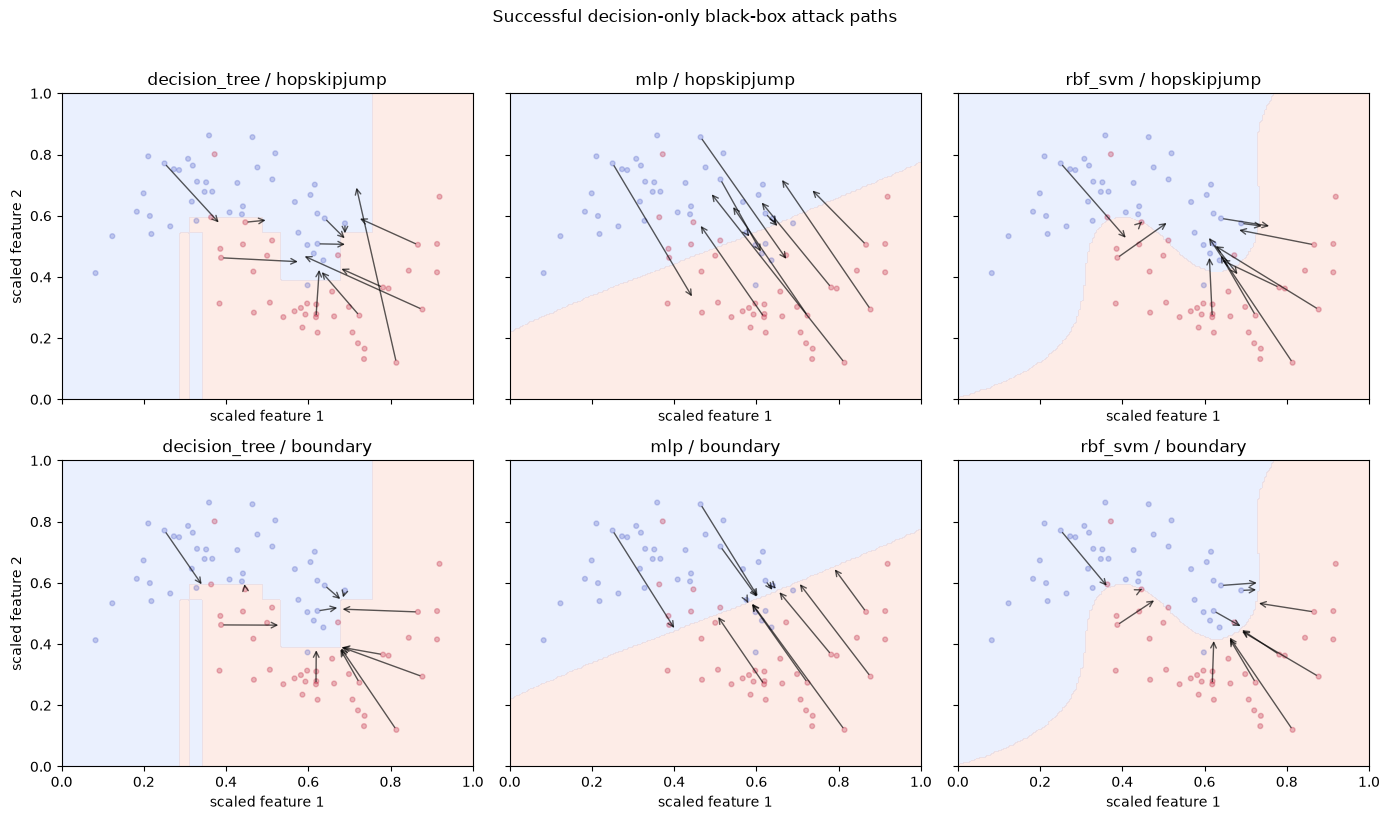

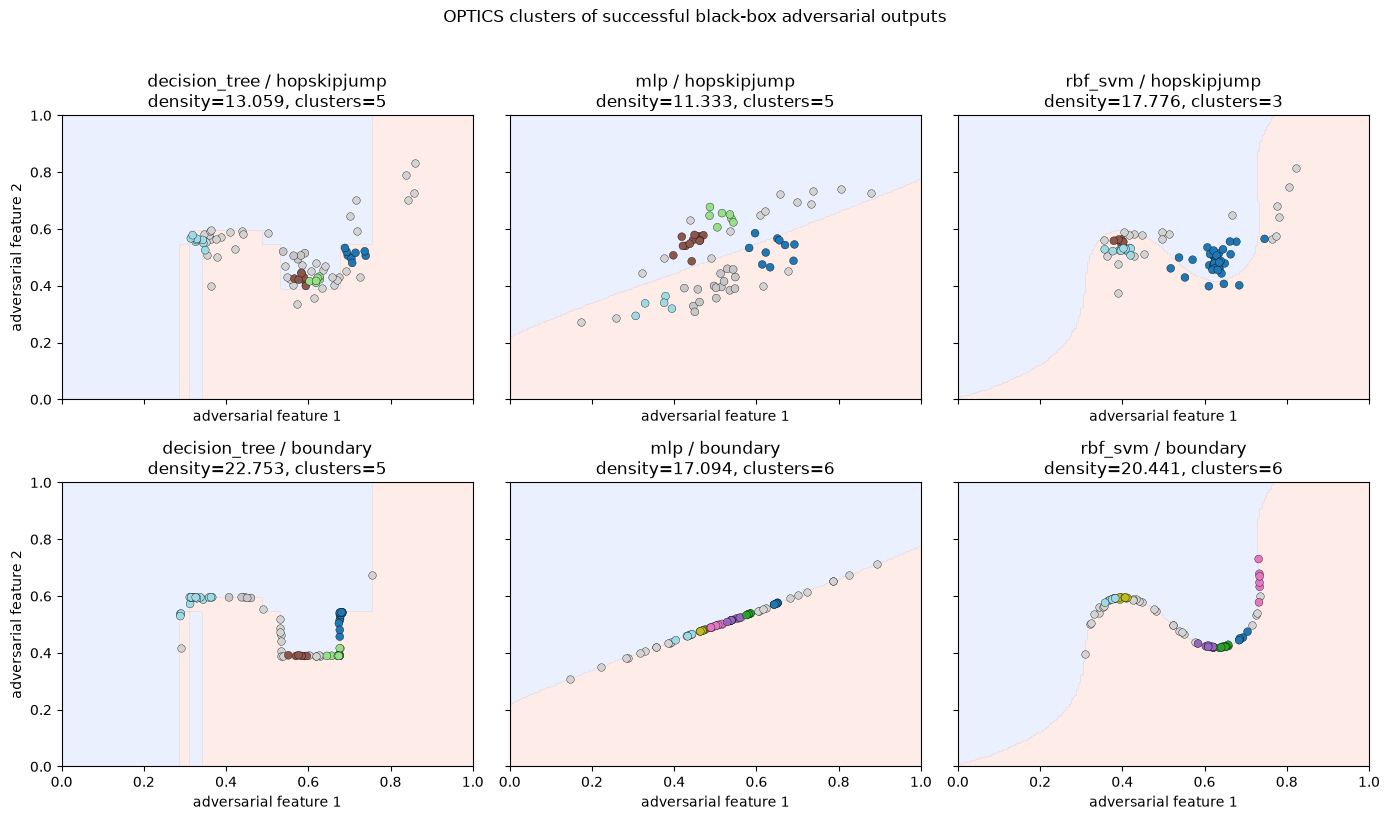

In [7]:
def draw_decision_regions(axis, model) -> None:
    grid_axis = np.linspace(0.0, 1.0, 180)
    grid_x0, grid_x1 = np.meshgrid(grid_axis, grid_axis)
    grid = np.column_stack([grid_x0.ravel(), grid_x1.ravel()])
    regions = model.predict(grid).reshape(grid_x0.shape)
    axis.contourf(
        grid_x0,
        grid_x1,
        regions,
        levels=[-0.5, 0.5, 1.5],
        cmap="coolwarm",
        alpha=0.18,
    )


fig, axes = plt.subplots(2, len(models), figsize=(14, 8), sharex=True, sharey=True)
for row, attack_name in enumerate(("hopskipjump", "boundary")):
    for column, (model_name, model) in enumerate(models.items()):
        axis = axes[row, column]
        draw_decision_regions(axis, model)
        examples = attack_results[
            (attack_results["model"] == model_name)
            & (attack_results["attack"] == attack_name)
            & attack_results["attack_success"]
        ].head(12)
        axis.scatter(
            X_attack[:, 0],
            X_attack[:, 1],
            c=y_attack,
            cmap="coolwarm",
            s=12,
            alpha=0.25,
        )
        for _, example in examples.iterrows():
            axis.annotate(
                "",
                xy=(example["adv_x0"], example["adv_x1"]),
                xytext=(example["x0"], example["x1"]),
                arrowprops={"arrowstyle": "->", "color": "black", "alpha": 0.65},
            )
        axis.set_title(f"{model_name} / {attack_name}")
        axis.set_xlabel("scaled feature 1")
        if column == 0:
            axis.set_ylabel("scaled feature 2")
fig.suptitle("Successful decision-only black-box attack paths", y=1.02)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "black_box_attack_paths.png", dpi=160, bbox_inches="tight")
plt.show()


fig, axes = plt.subplots(2, len(models), figsize=(14, 8), sharex=True, sharey=True)
for row, attack_name in enumerate(("hopskipjump", "boundary")):
    for column, (model_name, model) in enumerate(models.items()):
        axis = axes[row, column]
        draw_decision_regions(axis, model)
        subset = attack_results.loc[
            (attack_results["model"] == model_name)
            & (attack_results["attack"] == attack_name)
            & attack_results["clean_correct"]
            & attack_results["attack_success"]
        ].copy()
        noise = subset[subset["adversarial_cluster_label"] == -1]
        clustered = subset[subset["adversarial_cluster_label"] != -1]
        if not noise.empty:
            axis.scatter(
                noise["adv_x0"],
                noise["adv_x1"],
                c="lightgrey",
                edgecolor="black",
                linewidth=0.25,
                s=30,
                label="OPTICS noise",
            )
        if not clustered.empty:
            axis.scatter(
                clustered["adv_x0"],
                clustered["adv_x1"],
                c=clustered["adversarial_cluster_label"],
                cmap="tab20",
                edgecolor="black",
                linewidth=0.25,
                s=32,
                label="OPTICS cluster",
            )
        summary = cluster_summary[
            (cluster_summary["model"] == model_name)
            & (cluster_summary["attack"] == attack_name)
        ].iloc[0]
        density = summary["adversarial_cluster_density"]
        density_label = f"{density:.3f}" if pd.notna(density) else "n/a"
        axis.set(
            title=(
                f"{model_name} / {attack_name}\n"
                f"density={density_label}, clusters={int(summary['adversarial_cluster_count'])}"
            ),
            xlabel="adversarial feature 1",
        )
        if column == 0:
            axis.set_ylabel("adversarial feature 2")
fig.suptitle("OPTICS clusters of successful black-box adversarial outputs", y=1.02)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "adversarial_clusters.png", dpi=160, bbox_inches="tight")
plt.show()

## Interpretation checklist

- A high empirical reliability score means these two **query-bounded attacks** did not change many correct predictions within the selected L2 budget. It does not prove robustness.
- High adversarial-cluster density means a particular attack's successful outputs are tightly concentrated. It can identify a recurring failure region, but it does not by itself show that the model is less robust or predict an attack before it runs.
- Before applying this to a deployment, replace the two-moons data with a representative labelled audit set, define valid feature constraints (not just an L2 ball), repeat across seeds, and report class/group slices. Do not infer fairness from aggregate results alone.
- Compare cluster-density values only under the same feature scaling, attack configuration, and clustering configuration. Always report success rate, robust accuracy, successful-point count, cluster count, and noise count alongside it.